# 06 — Modelling and SHAP analysis

This notebook compares logistic regression, random forest and XGBoost for identifying player-seasons labelled as future elite. It then interprets model behaviour and compares model-based rankings with current market-value rankings.

**Outcome prevalence:** the supplied labelled dataset contains approximately 9% positive observations. Class weighting is used to address this imbalance without changing the test-set prevalence. Results are assessed using ROC-AUC, average precision (PR-AUC) and ranking-based scouting measures, rather than accuracy alone.

**Evaluation design:** observations are split by player using `GroupShuffleSplit`. A player's seasons therefore cannot appear in both the training and test sets. This reduces the risk of player-specific information leaking across the split.

Run the notebook from the project root, or change `PROJECT_ROOT` below if your notebook is stored elsewhere.


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import xgboost as xgb

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Project folders. This works when the notebook is run from the project root
# or from the notebooks/ directory.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "final_labeled_dataset.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place final_labeled_dataset.csv "
        "inside data/processed/."
    )


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load labeled dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape}")
print(f"Distinct players: {df['Player'].nunique():,}")
print(f"Positive-class rate: {df['is_elite'].mean():.1%}")


Dataset shape: (2764, 318)
Distinct players: 1,471
Positive-class rate: 9.0%


## 2. Feature selection

**Critical**: only observation-window performance features go in. Anything derived from the outcome window (`value_2yr_later`, `club_2yr_later`, `tier_future`, `breakout_composite`, `breakout_percentile`, and the three flag columns / `elite_score` themselves) must be excluded — including any of these would leak the label directly into the features.

In [3]:
FEATURES = [
    'xG90', 'xA90', 'xGBuildup90',   # xGChain90 dropped: correlates 0.78 with
                                      # xA90 and 0.77 with xGBuildup90 (checked
                                      # via df_model[[...]].corr()), causing
                                      # unstable/uninterpretable coefficient
                                      # signs in the Logistic Regression model.
                                      # Dropping the most redundant of the three
                                      # keeps distinct signal while removing the
                                      # worst of the multicollinearity.
    'TklW_per90', 'Int_per90', 'KP_per90', 'PrgP_per90', 'PrgC_per90', 'AerialWon_per90',
    'Min', 'Age',
]

missing = [f for f in FEATURES if f not in df.columns]
if missing:
    print(f"WARNING: these expected features are missing, check column names: {missing}")
FEATURES = [f for f in FEATURES if f in df.columns]

df['primary_pos'] = df['Pos'].str.split(',').str[0]
df = df[df['primary_pos'] != 'GK'].copy()
pos_dummies = pd.get_dummies(df['primary_pos'], prefix='pos')
df = pd.concat([df, pos_dummies], axis=1)
FEATURES = FEATURES + pos_dummies.columns.tolist()

print(f"Using {len(FEATURES)} features: {FEATURES}")
print(f"\nMissing values per feature:")
print(df[FEATURES].isna().sum())

Using 14 features: ['xG90', 'xA90', 'xGBuildup90', 'TklW_per90', 'Int_per90', 'KP_per90', 'PrgP_per90', 'PrgC_per90', 'AerialWon_per90', 'Min', 'Age', 'pos_DF', 'pos_FW', 'pos_MF']

Missing values per feature:
xG90               0
xA90               0
xGBuildup90        0
TklW_per90         0
Int_per90          0
KP_per90           0
PrgP_per90         0
PrgC_per90         0
AerialWon_per90    0
Min                0
Age                0
pos_DF             0
pos_FW             0
pos_MF             0
dtype: int64


## 3. Grouped train/test split (by player, not by row)

In [4]:
df_model = df.dropna(subset=['is_elite']).copy()

X = df_model[FEATURES]
y = df_model['is_elite'].astype(int)
groups = df_model['Player']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=772)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} rows, {y_train.mean():.1%} elite")
print(f"Test:  {len(X_test)} rows, {y_test.mean():.1%} elite")
print(f"No player overlap between train/test: "
      f"{len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])) == 0}")

Train: 2063 rows, 8.7% elite
Test:  701 rows, 10.0% elite
No player overlap between train/test: True


## 4. Impute missing values (median, fit on train only)

In [5]:
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)

## 5. Baseline: Logistic Regression

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=772)
logreg.fit(X_train_scaled, y_train)

y_pred_proba_lr = logreg.predict_proba(X_test_scaled)[:, 1]
y_pred_lr = logreg.predict(X_test_scaled)

print("Logistic Regression")
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_lr):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_pred_proba_lr):.3f}")

Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.67      0.77       631
           1       0.14      0.50      0.22        70

    accuracy                           0.65       701
   macro avg       0.53      0.58      0.50       701
weighted avg       0.85      0.65      0.72       701

ROC-AUC: 0.632
PR-AUC:  0.158


## 6. Random Forest

In [7]:
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                             max_depth=8, min_samples_leaf=5, random_state=772)
rf.fit(X_train_imp, y_train)

y_pred_proba_rf = rf.predict_proba(X_test_imp)[:, 1]
y_pred_rf = rf.predict(X_test_imp)

print("Random Forest")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_rf):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_pred_proba_rf):.3f}")

Random Forest
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       631
           1       0.09      0.03      0.04        70

    accuracy                           0.87       701
   macro avg       0.50      0.50      0.49       701
weighted avg       0.82      0.87      0.84       701

ROC-AUC: 0.623
PR-AUC:  0.152


## 7. XGBoost

In [8]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.1f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, eval_metric='aucpr',
    random_state=772
)
xgb_model.fit(X_train_imp, y_train)

y_pred_proba_xgb = xgb_model.predict_proba(X_test_imp)[:, 1]
y_pred_xgb = xgb_model.predict(X_test_imp)

print("XGBoost")
print(classification_report(y_test, y_pred_xgb))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba_xgb):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_pred_proba_xgb):.3f}")

scale_pos_weight: 10.5


XGBoost
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       631
           1       0.16      0.14      0.15        70

    accuracy                           0.84       701
   macro avg       0.53      0.53      0.53       701
weighted avg       0.83      0.84      0.84       701

ROC-AUC: 0.594
PR-AUC:  0.152


## 8. Model comparison summary

In [9]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'ROC-AUC': [
        roc_auc_score(y_test, y_pred_proba_lr),
        roc_auc_score(y_test, y_pred_proba_rf),
        roc_auc_score(y_test, y_pred_proba_xgb),
    ],
    'PR-AUC': [
        average_precision_score(y_test, y_pred_proba_lr),
        average_precision_score(y_test, y_pred_proba_rf),
        average_precision_score(y_test, y_pred_proba_xgb),
    ],
})
print(comparison.to_string(index=False))

              Model  ROC-AUC   PR-AUC
Logistic Regression 0.632352 0.158423
      Random Forest 0.623319 0.151785
            XGBoost 0.594046 0.151698


## 9. Model interpretation

The model comparison above determines which model has the strongest test-set average precision. Logistic regression is particularly useful for interpretation because its coefficients show the direction and relative strength of the association between each standardised feature and the predicted log-odds. The XGBoost SHAP plot is retained as a secondary view of feature contributions for a non-linear model.


        feature  coefficient
       KP_per90     0.655029
            Age    -0.521348
AerialWon_per90     0.414057
         pos_FW    -0.377999
           xG90     0.324337
           xA90    -0.299244
    xGBuildup90    -0.281153
            Min     0.252675
         pos_DF     0.180873
      Int_per90     0.170687
         pos_MF     0.157507
     TklW_per90    -0.109419
     PrgC_per90    -0.068404
     PrgP_per90    -0.012960


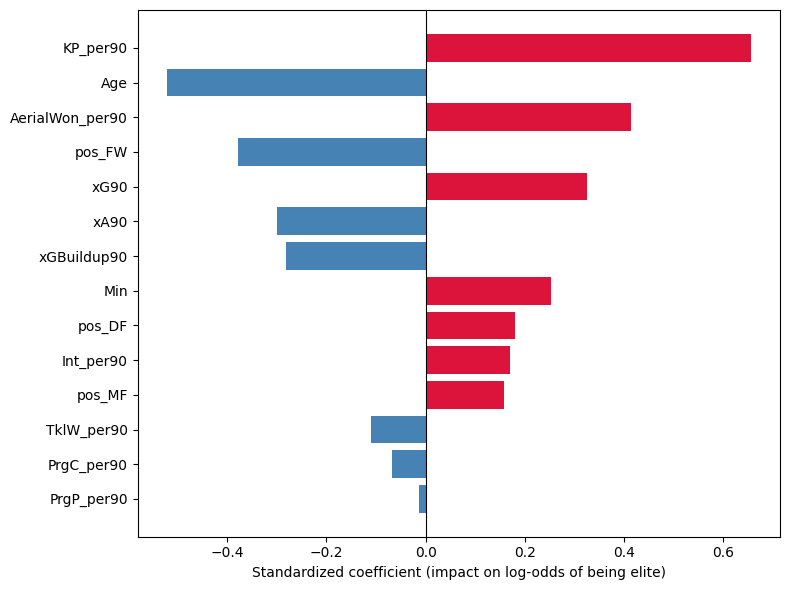

In [10]:
coef_df = pd.DataFrame({
    'feature': FEATURES,
    'coefficient': logreg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print(coef_df.to_string(index=False))

colors = ['crimson' if c > 0 else 'steelblue' for c in coef_df['coefficient']]
plt.figure(figsize=(8, 6))
plt.barh(coef_df['feature'], coef_df['coefficient'], color=colors)
plt.xlabel('Standardized coefficient (impact on log-odds of being elite)')
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logreg_coefficients.png", dpi=150)
plt.show()

Coefficients are on **standardized features** (via the `StandardScaler` fit in Section 5), so magnitudes are directly comparable across features — a positive coefficient increases the log-odds of being labelled elite for a one-standard-deviation increase in that feature; a negative coefficient decreases it.

### Secondary comparison — XGBoost SHAP

Shown for comparison against the primary (Logistic Regression) interpretation above, not as the lead result.

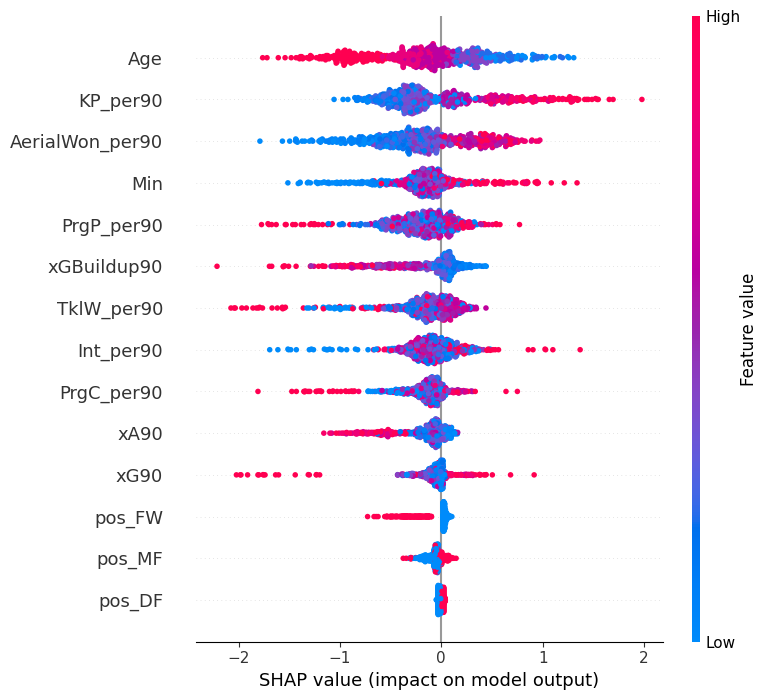

In [11]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_imp)

shap.summary_plot(shap_values, X_test_imp, feature_names=FEATURES, show=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary.png", dpi=150)
plt.show()

## 10. Case-study check

This section reports the fitted models' estimated probabilities for selected players in the labelled dataset. These predictions are descriptive: players may belong to either the training or test partition. For an out-of-sample case study, use only players in the held-out test group and identify their observation season explicitly.


In [12]:
case_study_players = ['Cole Palmer', 'Michael Olise', 'Randal Kolo Muani']
case_rows = df_model[df_model['Player'].isin(case_study_players)].copy()

case_X_imp = pd.DataFrame(imputer.transform(case_rows[FEATURES]), columns=FEATURES, index=case_rows.index)
case_X_scaled = scaler.transform(case_X_imp)

# Logistic Regression (primary model) prediction
case_rows['lr_predicted_probability'] = logreg.predict_proba(case_X_scaled)[:, 1]
# XGBoost (secondary comparison)
case_rows['xgb_predicted_probability'] = xgb_model.predict_proba(case_X_imp)[:, 1]

print(case_rows[['Player', 'Season', 'is_elite', 'lr_predicted_probability',
                  'xgb_predicted_probability', 'value_at_observation']]
      .sort_values(['Player', 'Season']).to_string(index=False))

           Player    Season  is_elite  lr_predicted_probability  xgb_predicted_probability  value_at_observation
      Cole Palmer 2023-2024     False                  0.448165                   0.045297            80000000.0
    Michael Olise 2021-2022     False                  0.150002                   0.233696            22000000.0
    Michael Olise 2022-2023     False                  0.644401                   0.572984            38000000.0
    Michael Olise 2023-2024      True                  0.368595                   0.319555            55000000.0
Randal Kolo Muani 2020-2021      True                  0.611757                   0.936305             9000000.0
Randal Kolo Muani 2021-2022      True                  0.596261                   0.931681            16000000.0
Randal Kolo Muani 2022-2023     False                  0.483600                   0.078894            80000000.0
Randal Kolo Muani 2023-2024     False                  0.233658                   0.060686      

## 11. Market-value scouting vs. model scouting comparison

Core evaluation for the dissertation's research question. A single top-20 snapshot is high-variance with only 60 positives in the test set — **Precision@K across several K values**, plus a cumulative gains chart, gives a steadier picture than any one cutoff. Uses Logistic Regression's probability as the model score, since it's the best-performing model.

In [13]:
test_rows = df_model.iloc[test_idx].copy()
test_rows['model_predicted_probability'] = y_pred_proba_lr  # Logistic Regression — best PR-AUC

def precision_at_k(df, score_col, k):
    top_k = df.nlargest(k, score_col)
    return top_k['is_elite'].mean(), int(top_k['is_elite'].sum())

Ks = [10, 20, 30, 50, 100]
results = []
for k in Ks:
    mv_prec, mv_hits = precision_at_k(test_rows, 'value_at_observation', k)
    model_prec, model_hits = precision_at_k(test_rows, 'model_predicted_probability', k)
    results.append({
        'K': k,
        'market_value_precision': mv_prec, 'market_value_hits': mv_hits,
        'model_precision': model_prec, 'model_hits': model_hits,
    })

precision_table = pd.DataFrame(results)
print(precision_table.to_string(index=False))

  K  market_value_precision  market_value_hits  model_precision  model_hits
 10                0.000000                  0         0.200000           2
 20                0.000000                  0         0.250000           5
 30                0.033333                  1         0.166667           5
 50                0.060000                  3         0.140000           7
100                0.050000                  5         0.160000          16


### Cumulative gains chart

What share of all future-elite players in the test set would each strategy have captured, selecting the top X% by that strategy's ranking?

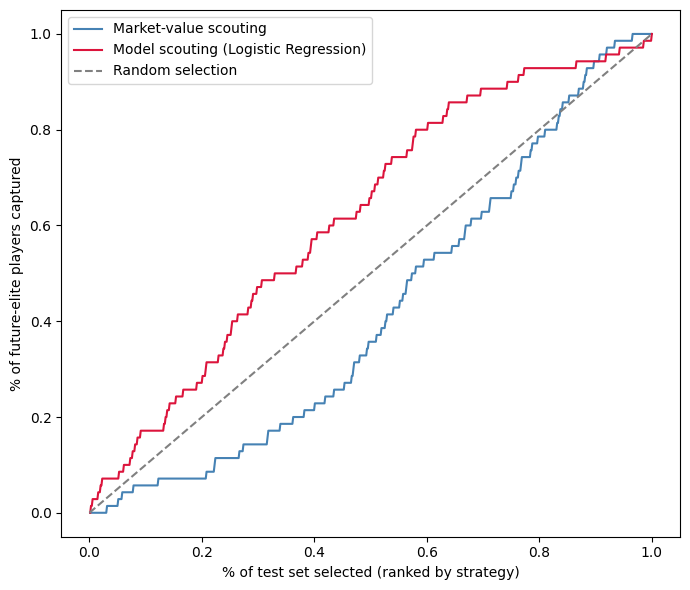

In [14]:
def cumulative_gains(df, score_col, label_col='is_elite'):
    sorted_df = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    total_positives = sorted_df[label_col].sum()
    cum_positives = sorted_df[label_col].cumsum()
    pct_population = (sorted_df.index + 1) / len(sorted_df)
    pct_positives_captured = cum_positives / total_positives
    return pct_population, pct_positives_captured

mv_x, mv_y = cumulative_gains(test_rows, 'value_at_observation')
model_x, model_y = cumulative_gains(test_rows, 'model_predicted_probability')

plt.figure(figsize=(7, 6))
plt.plot(mv_x, mv_y, label='Market-value scouting', color='steelblue')
plt.plot(model_x, model_y, label='Model scouting (Logistic Regression)', color='crimson')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random selection')
plt.xlabel('% of test set selected (ranked by strategy)')
plt.ylabel('% of future-elite players captured')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cumulative_gains_chart.png", dpi=150)
plt.show()

### Players the model flagged that market-value scouting missed (top 20, for illustration)

Kept as a qualitative supplement to the Precision@K table above — useful for picking specific named examples to discuss, not as the primary quantitative evidence.

In [15]:
N = 20
market_value_picks = test_rows.nlargest(N, 'value_at_observation')
model_picks = test_rows.nlargest(N, 'model_predicted_probability')

model_only = set(model_picks['Player']) - set(market_value_picks['Player'])
print(model_picks[model_picks['Player'].isin(model_only)][
    ['Player', 'Season', 'value_at_observation', 'model_predicted_probability', 'is_elite']
].to_string(index=False))

            Player    Season  value_at_observation  model_predicted_probability  is_elite
    Adil Aouchiche 2020-2021                   NaN                     0.942929     False
         Sidy Sarr 2019-2020             1600000.0                     0.847846     False
   Pape Matar Sarr 2021-2022            15000000.0                     0.822762      True
   Weston McKennie 2019-2020            20000000.0                     0.820731     False
Sebastiaan Bornauw 2019-2020            13000000.0                     0.789783     False
   Mathías Olivera 2021-2022            15000000.0                     0.785037     False
          Raphinha 2020-2021            30000000.0                     0.774976      True
       Fábio Silva 2020-2021            25000000.0                     0.766830     False
      Brajan Gruda 2023-2024            20000000.0                     0.765949      True
   Lilian Brassier 2020-2021             2500000.0                     0.762309      True
    Adil A

## 12. Save model outputs

In [16]:
test_rows.to_csv(TABLES_DIR / "test_set_predictions.csv", index=False)
case_rows.to_csv(TABLES_DIR / "case_study_predictions.csv", index=False)
print("Saved test_set_predictions.csv and case_study_predictions.csv")

Saved test_set_predictions.csv and case_study_predictions.csv


## 13. ROC and Precision-Recall curves

Visual complement to the ROC-AUC/PR-AUC table in Section 8 — useful for showing *where* along the threshold range each model's advantage comes from, not just the summary statistic.

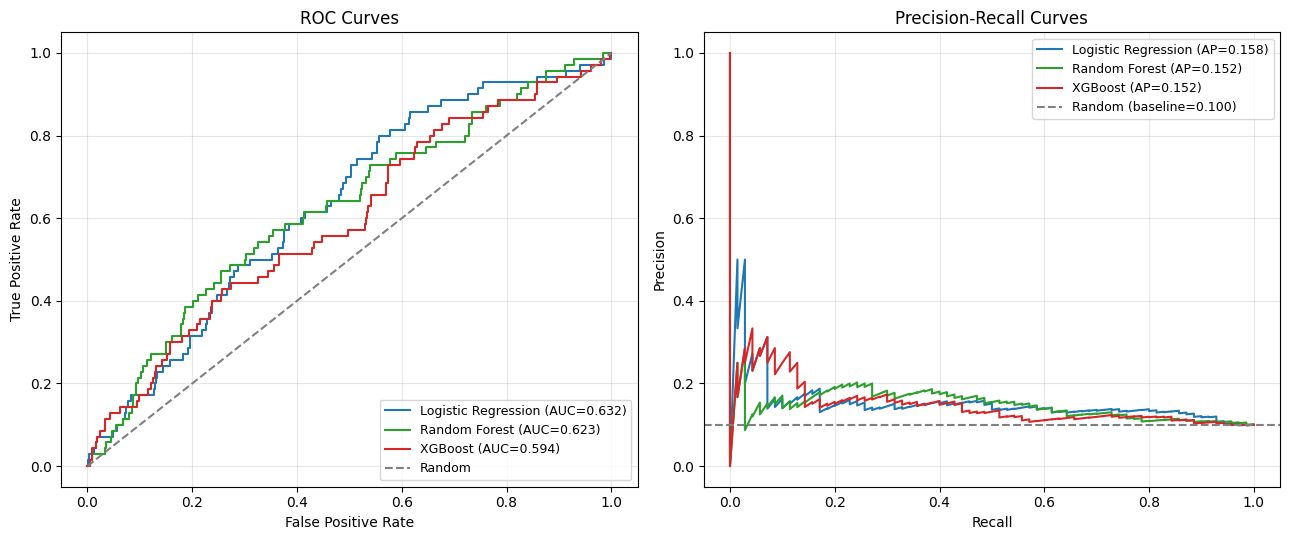

In [17]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

model_probas = {
    'Logistic Regression': y_pred_proba_lr,
    'Random Forest': y_pred_proba_rf,
    'XGBoost': y_pred_proba_xgb,
}
colors = {'Logistic Regression': '#1f77b4', 'Random Forest': '#2ca02c', 'XGBoost': '#d62728'}

# --- ROC curves ---
for name, proba in model_probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, proba):.3f})', color=colors[name])
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(alpha=0.3)

# --- Precision-Recall curves ---
baseline = y_test.mean()  # positive-class prevalence, the PR curve's random-baseline reference
for name, proba in model_probas.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f'{name} (AP={average_precision_score(y_test, proba):.3f})', color=colors[name])
axes[1].axhline(baseline, linestyle='--', color='gray', label=f'Random (baseline={baseline:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_pr_curves.png", dpi=150)
plt.show()

## 14. Confusion matrices

At the default 0.5 probability threshold, for all three models. Note this threshold is a nominal reference, not necessarily each model's optimal operating point given the class imbalance — worth stating explicitly in the write-up rather than implying 0.5 was tuned for.

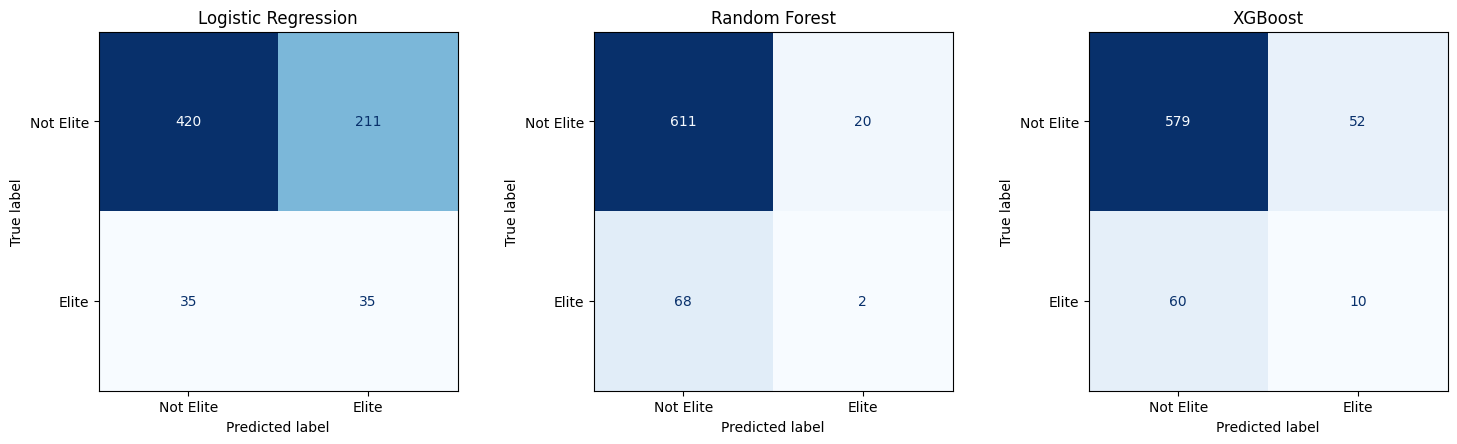

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

model_preds = {
    'Logistic Regression': (y_test, (y_pred_proba_lr >= 0.5).astype(int)),
    'Random Forest': (y_test, (y_pred_proba_rf >= 0.5).astype(int)),
    'XGBoost': (y_test, (y_pred_proba_xgb >= 0.5).astype(int)),
}

for ax, (name, (y_true, y_pred)) in zip(axes, model_preds.items()):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Elite', 'Elite'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## 15. Hyperparameters and preprocessing summary

Reference table for the dissertation appendix — documents exact settings used, for replicability.

In [19]:
config_summary = pd.DataFrame([
    {'Component': 'Train/test split', 'Setting': 'GroupShuffleSplit, grouped by Player, test_size=0.25, random_state=772'},
    {'Component': 'Missing value imputation', 'Setting': 'SimpleImputer, strategy="median", fit on train only'},
    {'Component': 'Feature scaling (LR only)', 'Setting': 'StandardScaler, fit on train only'},
    {'Component': 'Logistic Regression', 'Setting': "class_weight='balanced', max_iter=1000, random_state=772"},
    {'Component': 'Random Forest', 'Setting': "n_estimators=300, class_weight='balanced', max_depth=8, min_samples_leaf=5, random_state=772"},
    {'Component': 'XGBoost', 'Setting': f"n_estimators=300, max_depth=4, learning_rate=0.05, scale_pos_weight={scale_pos_weight:.1f}, eval_metric='aucpr', random_state=772"},
    {'Component': 'Classification threshold (confusion matrices)', 'Setting': '0.5 (nominal reference, not tuned per model)'},
    {'Component': 'Feature count', 'Setting': f'{len(FEATURES)} features (see Section 2)'},
])

print(config_summary.to_string(index=False))
config_summary.to_csv(TABLES_DIR / "model_config_summary.csv", index=False)

                                    Component                                                                                                         Setting
                             Train/test split                                          GroupShuffleSplit, grouped by Player, test_size=0.25, random_state=772
                     Missing value imputation                                                             SimpleImputer, strategy="median", fit on train only
                    Feature scaling (LR only)                                                                               StandardScaler, fit on train only
                          Logistic Regression                                                        class_weight='balanced', max_iter=1000, random_state=772
                                Random Forest                    n_estimators=300, class_weight='balanced', max_depth=8, min_samples_leaf=5, random_state=772
                                      XGBoost n_esti

In [20]:
from sklearn.linear_model import LogisticRegression

logreg_l1 = LogisticRegression(
    penalty='l1', solver='liblinear',  # liblinear required for L1
    C=1.0, class_weight='balanced', max_iter=1000, random_state=772
)
logreg_l1.fit(X_train_scaled, y_train)

coef_l1_df = pd.DataFrame({
    'feature': FEATURES,
    'ridge_coef': logreg.coef_[0],
    'lasso_coef': logreg_l1.coef_[0],
}).sort_values('lasso_coef', key=abs, ascending=False)

print(coef_l1_df.to_string(index=False))
print(f"\nFeatures zeroed out by Lasso: {coef_l1_df[coef_l1_df['lasso_coef'] == 0]['feature'].tolist()}")

from sklearn.metrics import roc_auc_score, average_precision_score
y_pred_proba_l1 = logreg_l1.predict_proba(X_test_scaled)[:, 1]
print(f"\nLasso ROC-AUC: {roc_auc_score(y_test, y_pred_proba_l1):.3f}")
print(f"Lasso PR-AUC: {average_precision_score(y_test, y_pred_proba_l1):.3f}")

        feature  ridge_coef  lasso_coef
       KP_per90    0.655029    0.638200
            Age   -0.521348   -0.518271
         pos_FW   -0.377999   -0.513538
AerialWon_per90    0.414057    0.414096
           xG90    0.324337    0.314476
           xA90   -0.299244   -0.287105
    xGBuildup90   -0.281153   -0.280621
            Min    0.252675    0.250711
      Int_per90    0.170687    0.165946
     TklW_per90   -0.109419   -0.106126
     PrgC_per90   -0.068404   -0.064442
         pos_DF    0.180873    0.013489
     PrgP_per90   -0.012960   -0.008916
         pos_MF    0.157507    0.000000

Features zeroed out by Lasso: ['pos_MF']

Lasso ROC-AUC: 0.632
Lasso PR-AUC: 0.159


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [21]:
import pandas as pd

# --- 0. Confirm which case-study players are actually in the test set ---
case_study_players = ['Cole Palmer', 'Michael Olise', 'Randal Kolo Muani', 'Raphinha']

train_players = set(df_model.iloc[train_idx]['Player'])
test_players = set(df_model.iloc[test_idx]['Player'])

for player in case_study_players:
    location = 'TEST' if player in test_players else ('TRAIN' if player in train_players else 'NOT FOUND')
    print(f"{player}: {location}")

# --- 1. Build the test set with both models' probabilities ---
test_rows = df_model.iloc[test_idx].copy()
test_rows['lr_predicted_probability'] = y_pred_proba_lr
test_rows['xgb_predicted_probability'] = y_pred_proba_xgb

n_test = len(test_rows)
print(f"\nTest set size: {n_test} player-seasons")

# --- 2. Rank and percentile, for each model, within the test set ---
# rank 1 = highest probability. method='min' means ties share the best rank.
for prob_col, prefix in [('lr_predicted_probability', 'lr'),
                          ('xgb_predicted_probability', 'xgb')]:
    test_rows[f'{prefix}_rank'] = test_rows[prob_col].rank(ascending=False, method='min').astype(int)
    test_rows[f'{prefix}_percentile'] = (1 - (test_rows[f'{prefix}_rank'] - 1) / n_test) * 100

# --- 3. Market-value rank and percentile within the test set ---
test_rows['market_value_rank'] = test_rows['value_at_observation'].rank(ascending=False, method='min')
test_rows['market_value_percentile'] = (1 - (test_rows['market_value_rank'] - 1) / n_test) * 100

# --- 4. Top-K flags for both models, at your existing K values ---
for k in [10, 20, 30, 50, 100]:
    test_rows[f'lr_in_top_{k}'] = test_rows['lr_rank'] <= k
    test_rows[f'xgb_in_top_{k}'] = test_rows['xgb_rank'] <= k

# --- 5. Report for each case-study player found in the test set ---
report_cols = ['Player', 'Season', 'lr_rank', 'lr_percentile',
               'xgb_rank', 'xgb_percentile',
               'market_value_rank', 'market_value_percentile']

for player in case_study_players:
    rows = test_rows[test_rows['Player'] == player]
    if rows.empty:
        print(f"\n{player}: not in test set — see training-set fallback below")
        continue
    print(f"\n=== {player} (test set, n={n_test}) ===")
    for _, r in rows.iterrows():
        print(f"  {r['Season']}: LR rank {int(r['lr_rank'])}/{n_test} "
              f"(top {100-r['lr_percentile']:.1f}%), "
              f"XGB rank {int(r['xgb_rank'])}/{n_test} "
              f"(top {100-r['xgb_percentile']:.1f}%), "
              f"market-value rank {int(r['market_value_rank'])}/{n_test} "
              f"(top {100-r['market_value_percentile']:.1f}%)")
        for k in [10, 20, 30, 50, 100]:
            in_lr = "YES" if r[f'lr_in_top_{k}'] else "no"
            in_mv = "YES" if r['market_value_rank'] <= k else "no"
            print(f"    Top-{k}: model={in_lr}, market-value={in_mv}")

# --- 6. Fallback: rank within TRAINING set for any player not in test ---
# Explicitly labelled as in-sample — the model saw this player's true label
# during fitting, so this is much weaker evidence than an out-of-sample rank.
train_rows = df_model.iloc[train_idx].copy()

# Need in-sample predictions for the training set too, using the already-fitted models
train_X_imp = pd.DataFrame(imputer.transform(train_rows[FEATURES]), columns=FEATURES, index=train_rows.index)
train_X_scaled = scaler.transform(train_X_imp)
train_rows['lr_predicted_probability'] = logreg.predict_proba(train_X_scaled)[:, 1]
train_rows['xgb_predicted_probability'] = xgb_model.predict_proba(train_X_imp)[:, 1]

n_train = len(train_rows)
for prob_col, prefix in [('lr_predicted_probability', 'lr'), ('xgb_predicted_probability', 'xgb')]:
    train_rows[f'{prefix}_rank'] = train_rows[prob_col].rank(ascending=False, method='min').astype(int)
    train_rows[f'{prefix}_percentile'] = (1 - (train_rows[f'{prefix}_rank'] - 1) / n_train) * 100

for player in case_study_players:
    if player in test_players:
        continue  # already reported above
    rows = train_rows[train_rows['Player'] == player]
    if rows.empty:
        continue
    print(f"\n=== {player} (TRAINING set, in-sample, n={n_train}) ===")
    for _, r in rows.iterrows():
        print(f"  {r['Season']}: LR rank {int(r['lr_rank'])}/{n_train} (in-sample), "
              f"XGB rank {int(r['xgb_rank'])}/{n_train} (in-sample)")

Cole Palmer: TRAIN
Michael Olise: TEST
Randal Kolo Muani: TRAIN
Raphinha: TEST

Test set size: 701 player-seasons

Cole Palmer: not in test set — see training-set fallback below

=== Michael Olise (test set, n=701) ===
  2022-2023: LR rank 98/701 (top 13.8%), XGB rank 44/701 (top 6.1%), market-value rank 101/701 (top 14.3%)
    Top-10: model=no, market-value=no
    Top-20: model=no, market-value=no
    Top-30: model=no, market-value=no
    Top-50: model=no, market-value=no
    Top-100: model=YES, market-value=no
  2023-2024: LR rank 448/701 (top 63.8%), XGB rank 178/701 (top 25.2%), market-value rank 50/701 (top 7.0%)
    Top-10: model=no, market-value=no
    Top-20: model=no, market-value=no
    Top-30: model=no, market-value=no
    Top-50: model=no, market-value=YES
    Top-100: model=no, market-value=YES
  2021-2022: LR rank 671/701 (top 95.6%), XGB rank 260/701 (top 36.9%), market-value rank 216/701 (top 30.7%)
    Top-10: model=no, market-value=no
    Top-20: model=no, market-valu

In [22]:
import pandas as pd

# Assumes test_rows already has lr_predicted_probability and xgb_predicted_probability
# columns (from the earlier ranking script), and 'is_elite' for the label.

raphinha_rows = test_rows[test_rows['Player'] == 'Raphinha'].sort_values('Season')

print(raphinha_rows[['Player', 'Season', 'is_elite',
                      'lr_predicted_probability', 'xgb_predicted_probability']].to_string(index=False))

  Player    Season  is_elite  lr_predicted_probability  xgb_predicted_probability
Raphinha 2019-2020      True                  0.705295                   0.437379
Raphinha 2020-2021      True                  0.774976                   0.540580
Raphinha 2021-2022     False                  0.382273                   0.202815


---
## Reproducibility notes

- The split is grouped by `Player` and uses a fixed random seed (`772`).
- Imputation and scaling are fitted on the training data only.
- The confusion matrices use a nominal probability threshold of 0.5; this threshold is not tuned.
- Figures and tables are saved under `results/figures/` and `results/tables/`.
- This notebook starts from the final labelled dataset. The upstream collection and matching notebooks require additional raw source files documented in `data/README.md`.
